# NumCompute Streaming Classification Demo

This notebook demonstrates CSV chunk input, buffered decision-tree learning, prequential evaluation and visualisation using `numcompute_stream`.

**Evaluation order:** predict and score each incoming chunk before learning from it. Warm-up samples are excluded from evaluation. An incomplete final training buffer is retained without automatic flushing.

**Run:** select the project's Python environment and use **Restart Kernel and Run All** after the notebook is complete. Run from the repository root or its `demo` directory.

## Environment and project paths

The following cell locates the repository, imports its local implementation and prints the active environment. Paths are resolved relative to the working directory rather than a machine-specific absolute path.

In [1]:
import sys
from pathlib import Path
from importlib.metadata import version

candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
ROOT = next(
    (p for p in candidates
     if (p / 'pyproject.toml').is_file()
     and (p / 'numcompute_stream').is_dir()
     and (p / 'demo' / 'data' / 'stream_classification.csv').is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError('Run from the repository root or demo directory.')

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib
import numcompute_stream

package_path = Path(numcompute_stream.__file__).resolve()
assert package_path.parent == (ROOT / 'numcompute_stream').resolve(), 'Unexpected package location; restart with the project kernel.'

DATA_PATH = ROOT / 'demo' / 'data' / 'stream_classification.csv'
SOURCE_PATH = ROOT / 'demo' / 'data' / 'stream_classification_source.md'
assert SOURCE_PATH.is_file(), SOURCE_PATH

print('Python:', sys.version.split()[0])
print('Python executable:', sys.executable)
print('NumPy:', np.__version__)
print('Matplotlib:', matplotlib.__version__)
print('IPython:', version('ipython'))
print('Repository:', ROOT)
print('Package:', package_path)
print('Dataset:', DATA_PATH.relative_to(ROOT))

Python: 3.12.6
Python executable: c:\Users\14035\OneDrive\桌面\Assignment 2.2 NumCompute ML Framework\NumCompute-Assignment-2.2\.venv\Scripts\python.exe
NumPy: 2.5.5
Matplotlib: 3.11.2
IPython: 9.18.1
Repository: C:\Users\14035\OneDrive\桌面\Assignment 2.2 NumCompute ML Framework\NumCompute-Assignment-2.2
Package: C:\Users\14035\OneDrive\桌面\Assignment 2.2 NumCompute ML Framework\NumCompute-Assignment-2.2\numcompute_stream\__init__.py
Dataset: demo\data\stream_classification.csv


## Dataset and provenance

The course does not prescribe a dataset. This demo uses a locally generated synthetic binary classification CSV with 1,200 rows, three numeric features (`x1`, `x2`, `x3`) and an integer `target` label.

The target is generated from thresholds on `x1` and `x2`, followed by random label flips. Feature missingness is introduced after label generation. `x3` is a noise feature.

CSV row order simulates arrival order; there are no real timestamps or intentional concept drift. These results demonstrate framework behaviour and do not establish real-world predictive performance.

The generation rules and seed are recorded below.

In [2]:
print(SOURCE_PATH.read_text(encoding='utf-8'))

# Synthetic streaming classification data

Generated locally for this assignment using NumPy; no external dataset was used.

- Generator: numpy.random.default_rng(2026).
- Rows: 1200; numeric features: x1, x2, x3.
- Features: independent standard normal draws.
- Target: int((x1 > 0.25) or (x2 < -0.5)).
- Each target is independently flipped with probability 0.05.
- After target generation, each feature value is independently replaced with an empty field with probability 0.05.
- Random draws occur in this order: features, label flips, feature missingness.
- x3 is a noise feature; target values are never missing.
- CSV row order defines the simulated arrival order. There are no real timestamps or intentional concept drift.
- This dataset demonstrates functionality; results do not establish performance on real-world data.
- Generation environment: NumPy 1.26.4.



## Streaming learning and evaluation

CSV rows arrive in chunks of 128. The Pipeline owns the raw training
buffer and retrains when it contains at least 300 samples. Each retraining
uses the entire buffer, rebuilding preprocessing and the tree together.

Each chunk is scored before learning. The first three chunks are warm-up
and are excluded from evaluation. Rolling metrics use the latest 200
evaluated samples. The final incomplete training buffer is not flushed.

Predictions and their original row positions are retained for plotting
and an independent accuracy check. These demo arrays consume additional
memory beyond the trainer's reported array storage.

In [3]:
from numcompute_stream import (
    DecisionTreeClassifier,
    Imputer,
    Pipeline,
    StandardScaler,
    StreamTrainer,
    iter_csv_chunks,
)

CHUNK_SIZE = 128
BUFFER_SIZE = 300
WINDOW_SIZE = 200

# Recreate all state so rerunning this cell starts a fresh experiment.
model = Pipeline([
    ("imputer", Imputer()),
    ("scaler", StandardScaler()),
    ("tree", DecisionTreeClassifier(
        max_depth=5,
        buffer_size=BUFFER_SIZE,
        random_state=2026,
    )),
])
trainer = StreamTrainer(
    model,
    window_size=WINDOW_SIZE,
    classes=[0, 1],
    positive_label=1,
)

score_records = []
truth_chunks = []
prediction_chunks = []
sample_index_chunks = []
training_sizes = []
retrain_chunks = []
rows_seen = 0
missing_count = 0

for chunk_id, (X, y) in enumerate(
    iter_csv_chunks(
        DATA_PATH,
        target_column="target",
        label_dtype="int",
        chunk_size=CHUNK_SIZE,
    ),
    start=1,
):
    row_indices = np.arange(rows_seen + 1, rows_seen + len(y) + 1)
    missing_count += int(np.isnan(X).sum())

    # Capture predictions from the model available before learning.
    if model.is_fitted_:
        truth_chunks.append(y.copy())
        prediction_chunks.append(model.predict(X))
        sample_index_chunks.append(row_indices)

    version_before = model.model_version_
    retrains_before = model.n_retrains_
    buffer_before = model.n_samples_buffered_

    record = trainer.score_chunk(X, y)
    score_records.append(record)

    assert model.model_version_ == version_before
    assert model.n_samples_buffered_ == buffer_before

    evaluated_before_fit = trainer.n_samples_evaluated_
    trainer.fit_chunk(X, y)
    assert trainer.n_samples_evaluated_ == evaluated_before_fit

    if model.n_retrains_ > retrains_before:
        retrain_chunks.append(chunk_id)
        training_sizes.append(model.n_samples_fit_)

    rows_seen += len(y)
    print(
        f"chunk={chunk_id:2d} rows={len(y):3d} "
        f"warm_up={str(record['warm_up']):5s} "
        f"scored_version={record['model_version']} "
        f"active_version={model.model_version_} "
        f"buffer={model.n_samples_buffered_:3d}"
    )

y_true_eval = np.concatenate(truth_chunks)
y_pred_eval = np.concatenate(prediction_chunks)
evaluated_row_indices = np.concatenate(sample_index_chunks)
metrics = trainer.metrics_result()
event_logs = trainer.logs_

# Expected lifecycle for this dataset and the configuration above.
assert rows_seen == 1200
assert missing_count == 154
assert trainer.n_samples_evaluated_ == 816
assert [r["warm_up"] for r in score_records] == [True] * 3 + [False] * 7
assert retrain_chunks == [3, 6, 9]
assert training_sizes == [384, 384, 384]
assert model.n_samples_buffered_ == 48
assert [r["event"] for r in event_logs] == ["score", "fit"] * 10
assert all(r["success"] for r in event_logs)

np.testing.assert_array_equal(
    evaluated_row_indices, np.arange(385, 1201)
)
np.testing.assert_allclose(
    metrics["cumulative"]["accuracy"],
    np.mean(y_true_eval == y_pred_eval),
)
np.testing.assert_allclose(
    metrics["rolling"]["accuracy"],
    np.mean(y_true_eval[-WINDOW_SIZE:] == y_pred_eval[-WINDOW_SIZE:]),
)

print()
print("Rows read:", rows_seen)
print("Missing feature values:", missing_count)
print("Evaluated samples:", trainer.n_samples_evaluated_)
print("Retrain chunks:", retrain_chunks)
print("Training sizes:", training_sizes)
print("Remaining buffer:", model.n_samples_buffered_)
print("Log events:", len(event_logs))
print("Cumulative accuracy:", metrics["cumulative"]["accuracy"])
print("Rolling accuracy:", metrics["rolling"]["accuracy"])
print("Cumulative AUC:", metrics["cumulative_auc"]["auc"])
print("Rolling AUC:", metrics["rolling_auc"]["auc"])
print("Streaming evaluation checks: PASS")

chunk= 1 rows=128 warm_up=True  scored_version=0 active_version=0 buffer=128
chunk= 2 rows=128 warm_up=True  scored_version=0 active_version=0 buffer=256
chunk= 3 rows=128 warm_up=True  scored_version=0 active_version=1 buffer=  0
chunk= 4 rows=128 warm_up=False scored_version=1 active_version=1 buffer=128
chunk= 5 rows=128 warm_up=False scored_version=1 active_version=1 buffer=256
chunk= 6 rows=128 warm_up=False scored_version=1 active_version=2 buffer=  0
chunk= 7 rows=128 warm_up=False scored_version=2 active_version=2 buffer=128
chunk= 8 rows=128 warm_up=False scored_version=2 active_version=2 buffer=256
chunk= 9 rows=128 warm_up=False scored_version=2 active_version=3 buffer=  0
chunk=10 rows= 48 warm_up=False scored_version=3 active_version=3 buffer= 48

Rows read: 1200
Missing feature values: 154
Evaluated samples: 816
Retrain chunks: [3, 6, 9]
Training sizes: [384, 384, 384]
Remaining buffer: 48
Log events: 20
Cumulative accuracy: 0.9080882352941176
Rolling accuracy: 0.9
Cumula

## Accuracy over the stream

Cumulative accuracy is calculated over all evaluated samples so far.
The first three chunks are warm-up and have no accuracy value.

Missing values remain at their original chunk positions. The first
visible point is chunk 4. This curve describes the synthetic demo run,
not a performance benchmark.

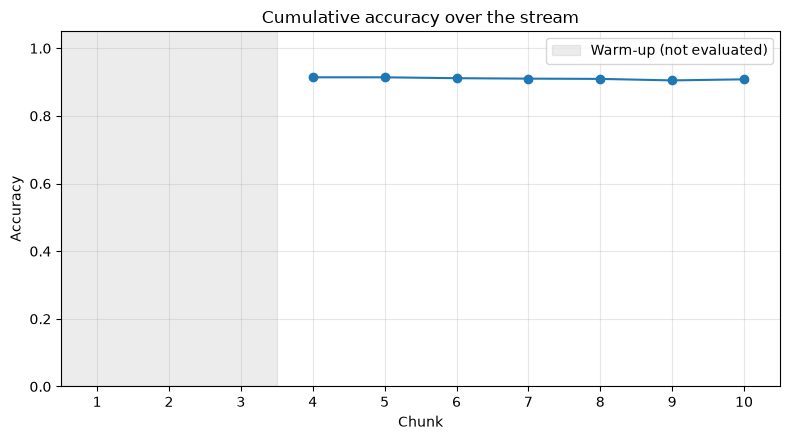

Saved: demo\figures\stream_cumulative_accuracy.png
Metric figure check: PASS


In [4]:
%matplotlib inline

import matplotlib.pyplot as plt

from numcompute_stream import plot_metric_over_time

FIGURE_DIR = ROOT / "demo" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

chunk_ids = np.array([record["score_id"] for record in score_records])
cumulative_accuracy = np.array([
    record["cumulative_accuracy"] for record in score_records
])

assert np.isnan(cumulative_accuracy[:3]).all()
assert np.isfinite(cumulative_accuracy[3:]).all()

metric_path = FIGURE_DIR / "stream_cumulative_accuracy.png"

fig, ax = plot_metric_over_time(
    cumulative_accuracy,
    "Cumulative accuracy over the stream",
    "Accuracy",
    x_values=chunk_ids,
)

try:
    # Keep warm-up positions visible even though their values are NaN.
    ax.set_xlim(0.5, len(chunk_ids) + 0.5)
    ax.set_xticks(chunk_ids)
    ax.set_ylim(0.0, 1.05)
    ax.axvspan(
        0.5, 3.5,
        color="grey",
        alpha=0.15,
        label="Warm-up (not evaluated)",
    )
    ax.legend()
    fig.tight_layout()

    # Save after adding the demo-specific annotations.
    fig.savefig(metric_path, bbox_inches="tight")
    assert metric_path.is_file() and metric_path.stat().st_size > 0

    plt.show()
finally:
    plt.close(fig)

print("Saved:", metric_path.relative_to(ROOT))
print("Metric figure check: PASS")

## Comparing two buffer configurations

Both models receive the same CSV rows in the same order, with a chunk
size of 128 and identical preprocessing, tree parameters and random seed.

The buffer-300 model first trains after chunk 3, using 384 rows.
The buffer-600 model first trains after chunk 5, using 640 rows.

The plot compares chunk accuracy only where both models can predict:
chunks 6–10. Earlier positions remain NaN. Each plotted value describes
the same incoming samples for both models, scored before learning.

This is a demonstration of model comparison, not a timing benchmark.
Chunk 10 contains only 48 samples; the other plotted chunks contain 128.
An unweighted average of these points would not be overall accuracy.

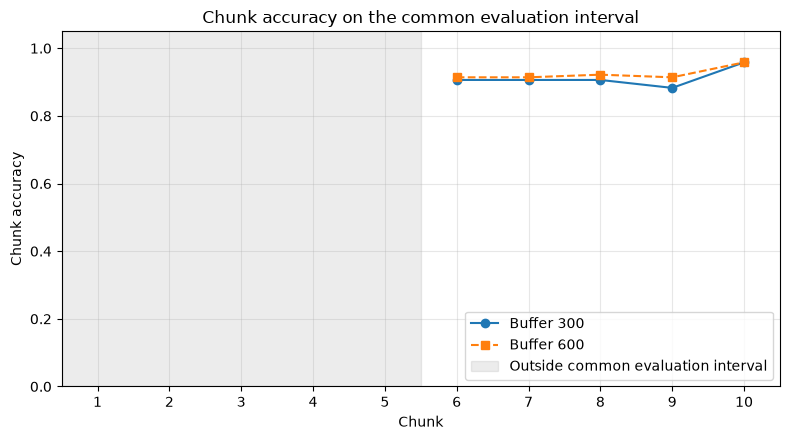

Buffer 600 retrain chunks: [5]
Buffer 600 training sizes: [640]
Buffer 600 remaining buffer: 560
Common evaluation chunks: [6, 7, 8, 9, 10]
Chunk sizes: [128, 128, 128, 128, 48]
Buffer 300 chunk accuracy: [0.90625, 0.90625, 0.90625, 0.8828125, 0.9583333333333334]
Buffer 600 chunk accuracy: [0.9140625, 0.9140625, 0.921875, 0.9140625, 0.9583333333333334]
Saved: demo\figures\stream_buffer_comparison.png
Model comparison figure check: PASS


In [5]:
from numcompute_stream import compare_models

# Use independent state; leave the original trainer and results unchanged.
comparison_model = Pipeline([
    ("imputer", Imputer()),
    ("scaler", StandardScaler()),
    ("tree", DecisionTreeClassifier(
        max_depth=5,
        buffer_size=600,
        random_state=2026,
    )),
])
comparison_trainer = StreamTrainer(
    comparison_model,
    window_size=WINDOW_SIZE,
    classes=[0, 1],
    positive_label=1,
)

comparison_records = []
comparison_training_sizes = []
comparison_retrain_chunks = []

for chunk_id, (X, y) in enumerate(
    iter_csv_chunks(
        DATA_PATH,
        target_column="target",
        label_dtype="int",
        chunk_size=CHUNK_SIZE,
    ),
    start=1,
):
    record = comparison_trainer.score_chunk(X, y)
    comparison_records.append(record)

    previous_retrains = comparison_model.n_retrains_
    comparison_trainer.fit_chunk(X, y)

    if comparison_model.n_retrains_ > previous_retrains:
        comparison_retrain_chunks.append(chunk_id)
        comparison_training_sizes.append(comparison_model.n_samples_fit_)

assert [r["warm_up"] for r in comparison_records] == (
    [True] * 5 + [False] * 5
)
assert comparison_retrain_chunks == [5]
assert comparison_training_sizes == [640]
assert comparison_trainer.n_samples_evaluated_ == 560
assert comparison_model.n_samples_buffered_ == 560

# Confirm that both record sequences refer to identical chunk positions.
assert [r["score_id"] for r in comparison_records] == (
    [r["score_id"] for r in score_records]
)
assert [r["chunk_size"] for r in comparison_records] == (
    [r["chunk_size"] for r in score_records]
)

common_mask = np.array([
    not first["warm_up"] and not second["warm_up"]
    for first, second in zip(score_records, comparison_records)
])
assert common_mask.tolist() == [False] * 5 + [True] * 5

accuracy_300 = np.array([
    r["chunk_accuracy"] for r in score_records
])
accuracy_600 = np.array([
    r["chunk_accuracy"] for r in comparison_records
])

# Retain original chunk positions while hiding non-comparable points.
common_accuracy_300 = np.where(common_mask, accuracy_300, np.nan)
common_accuracy_600 = np.where(common_mask, accuracy_600, np.nan)

comparison_path = FIGURE_DIR / "stream_buffer_comparison.png"

fig, ax = compare_models(
    common_accuracy_300,
    common_accuracy_600,
    ["Buffer 300", "Buffer 600"],
    x_values=chunk_ids,
    title="Chunk accuracy on the common evaluation interval",
    ylabel="Chunk accuracy",
)

try:
    ax.set_xlim(0.5, len(chunk_ids) + 0.5)
    ax.set_xticks(chunk_ids)
    ax.set_ylim(0.0, 1.05)
    ax.axvspan(
        0.5, 5.5,
        color="grey",
        alpha=0.15,
        label="Outside common evaluation interval",
    )
    ax.legend()
    fig.tight_layout()
    fig.savefig(comparison_path, bbox_inches="tight")
    assert comparison_path.is_file()
    assert comparison_path.stat().st_size > 0
    plt.show()
finally:
    plt.close(fig)

print("Buffer 600 retrain chunks:", comparison_retrain_chunks)
print("Buffer 600 training sizes:", comparison_training_sizes)
print("Buffer 600 remaining buffer:", comparison_model.n_samples_buffered_)
print("Common evaluation chunks:", chunk_ids[common_mask].tolist())
print("Chunk sizes:", [
    record["chunk_size"]
    for record, included in zip(score_records, common_mask)
    if included
])
print("Buffer 300 chunk accuracy:", accuracy_300[common_mask].tolist())
print("Buffer 600 chunk accuracy:", accuracy_600[common_mask].tolist())
print("Saved:", comparison_path.relative_to(ROOT))
print("Model comparison figure check: PASS")

## Predictions versus ground truth

This plot shows the first 50 evaluated samples from the buffer-300 run,
at original data row positions 385–434 (excluding the CSV header).

Predictions were recorded before learning from each incoming chunk.
They are not recomputed using the final model. The displayed subset is
fixed by arrival order rather than selected by prediction correctness.

An orange cross inside a blue circle indicates a correct prediction.
Markers at different class levels for the same sample indicate an error.
The displayed subset accuracy is separate from the full-stream accuracy.

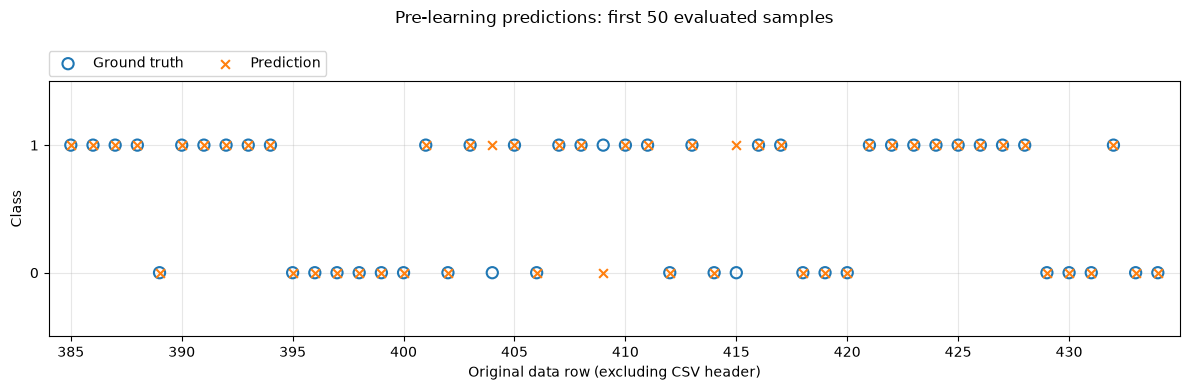

Model: Buffer 300
Displayed data rows: 385 to 434
Displayed samples: 50
Incorrect predictions in displayed subset: 3
Displayed subset accuracy: 0.94
Full evaluated-stream accuracy: 0.9080882352941176
Saved: demo\figures\stream_predictions_vs_truth.png
Prediction figure check: PASS


In [6]:
from numcompute_stream import plot_predictions_vs_ground_truth

N_DISPLAY = 50

display_truth = y_true_eval[:N_DISPLAY]
display_prediction = y_pred_eval[:N_DISPLAY]
display_indices = evaluated_row_indices[:N_DISPLAY]

assert len(display_truth) == N_DISPLAY
np.testing.assert_array_equal(
    display_indices, np.arange(385, 435)
)

display_errors = int(np.count_nonzero(
    display_truth != display_prediction
))
display_accuracy = float(np.mean(
    display_truth == display_prediction
))

prediction_path = FIGURE_DIR / "stream_predictions_vs_truth.png"

fig, ax = plot_predictions_vs_ground_truth(
    display_truth,
    display_prediction,
    sample_indices=display_indices,
    title="Pre-learning predictions: first 50 evaluated samples",
)

try:
    # Increase spacing so individual sample markers remain readable.
    fig.set_size_inches(12, 4)
    ax.set_xlabel("Original data row (excluding CSV header)")
    ax.set_xlim(display_indices[0] - 1, display_indices[-1] + 1)
    ax.set_xticks(np.arange(385, 435, 5))

    # Place the legend above the axes, away from the class markers.
    ax.legend(
        loc="lower left",
        bbox_to_anchor=(0, 1.02),
        ncol=2,
        borderaxespad=0,
    )
    ax.set_title(
        "Pre-learning predictions: first 50 evaluated samples",
        pad=42,
    )
    fig.tight_layout()
    fig.savefig(prediction_path, bbox_inches="tight")

    assert prediction_path.is_file()
    assert prediction_path.stat().st_size > 0
    plt.show()
finally:
    plt.close(fig)

print("Model: Buffer 300")
print("Displayed data rows:",
      int(display_indices[0]), "to", int(display_indices[-1]))
print("Displayed samples:", N_DISPLAY)
print("Incorrect predictions in displayed subset:", display_errors)
print("Displayed subset accuracy:", display_accuracy)
print("Full evaluated-stream accuracy:",
      metrics["cumulative"]["accuracy"])
print("Saved:", prediction_path.relative_to(ROOT))
print("Prediction figure check: PASS")

## Streaming descriptive statistics

A separate CSV pass updates StreamingStats from raw feature chunks.
This does not retrain either model or update evaluation metrics.

Counts, means and population variances exclude NaN values per feature.
Quantiles are exact global quantiles over retained valid observations,
not averages of chunk quantiles. Their storage grows with the data.

Histograms use fixed edges shared by all chunks. Values outside the
configured range do not enter histogram bins, but still contribute to
counts, moments and quantiles. The final bin includes its right edge.

These statistics describe all 1,200 input rows, including model warm-up
rows. They are not used to preprocess or train earlier predictions.

In [7]:
from numcompute_stream import StreamingStats

# Fixed before reading; not estimated from future chunks.
bin_edges = np.array([-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0])
stream_stats = StreamingStats(bin_edges=bin_edges)

stats_rows = 0
stats_missing = 0
outside_counts = np.zeros(3, dtype=np.int64)

for X, _ in iter_csv_chunks(
    DATA_PATH,
    target_column="target",
    label_dtype="int",
    chunk_size=CHUNK_SIZE,
):
    stream_stats.update_stats(X)
    stats_rows += X.shape[0]
    stats_missing += int(np.isnan(X).sum())
    outside_counts += np.count_nonzero(
        (X < bin_edges[0]) | (X > bin_edges[-1]),
        axis=0,
    )

stats_result = stream_stats.result()
quantile_levels = np.array([0.25, 0.5, 0.75])
quantile_values = stream_stats.quantile(quantile_levels)
histogram_result = stream_stats.histogram()

valid_counts = stats_result["count"]
histogram_counts = histogram_result["counts"]

assert stats_rows == 1200
assert stats_result["n_rows"] == stats_rows
assert stats_missing == 154
assert int(valid_counts.sum()) == stats_rows * 3 - stats_missing
assert quantile_values.shape == (3, 3)
assert histogram_counts.shape == (3, len(bin_edges) - 1)
np.testing.assert_array_equal(
    histogram_result["bin_edges"], bin_edges
)
np.testing.assert_array_equal(
    histogram_counts.sum(axis=1) + outside_counts,
    valid_counts,
)

# The independent statistics pass must not change trainer state.
assert trainer.n_samples_evaluated_ == 816
assert model.n_retrains_ == 3
assert len(trainer.logs_) == 20

print("Raw rows processed:", stats_rows)
print("Missing feature values:", stats_missing)
print()
print(
    f"{'Feature':<9} {'Count':>7} {'Mean':>11} {'Variance':>11} "
    f"{'Q25':>11} {'Median':>11} {'Q75':>11}"
)

for index, name in enumerate(("x1", "x2", "x3")):
    print(
        f"{name:<9} "
        f"{int(valid_counts[index]):>7d} "
        f"{stats_result['mean'][index]:>11.6f} "
        f"{stats_result['var'][index]:>11.6f} "
        f"{quantile_values[0, index]:>11.6f} "
        f"{quantile_values[1, index]:>11.6f} "
        f"{quantile_values[2, index]:>11.6f}"
    )

print()
print("Histogram edges:", histogram_result["bin_edges"])
print("Histogram counts (rows=x1,x2,x3; columns=bins):")
print(histogram_counts)
print("Valid observations outside histogram range:", outside_counts)
print("Streaming statistics checks: PASS")

Raw rows processed: 1200
Missing feature values: 154

Feature     Count        Mean    Variance         Q25      Median         Q75
x1           1153   -0.033734    1.010815   -0.729306   -0.016461    0.673165
x2           1135   -0.008107    1.010329   -0.702705    0.020159    0.656852
x3           1158    0.000532    0.998575   -0.699018    0.035850    0.701622

Histogram edges: [-3. -2. -1.  0.  1.  2.  3.]
Histogram counts (rows=x1,x2,x3; columns=bins):
[[ 27 167 387 399 147  24]
 [ 25 171 365 402 149  20]
 [ 28 146 390 404 170  18]]
Valid observations outside histogram range: [2 3 2]
Streaming statistics checks: PASS


## Event logs, timing and array storage

The buffer-300 trainer records one score event followed by one fit event
for each chunk. The table below shows the model version and pending
buffer after each event.

- `score_seconds` includes validation, prediction, metric copying,
  updates and result calculation.
- `training_seconds` measures the learning call, including validation,
  buffering and any preprocessing/tree rebuild. It is not isolated
  decision-tree training time.
- Both timings exclude the subsequent memory measurement and log
  insertion. They also exclude CSV reading, plotting and the extra
  predictions retained separately for this demo.

`memory_bytes` reports reachable NumPy array storage in the trainer's
model and evaluation state. `buffer_array_bytes` is a subset of that
amount and must not be added to it.

This measure is not process RAM or peak memory. It excludes Python-object
overhead, log-object storage, the separate statistics object, the second
trainer, plotting objects and the demo's separately retained predictions.
Object-array element storage is not fully represented by array nbytes.

Exact cumulative AUC, statistics history and event logs can grow with
the stream. These measurements do not establish constant-memory behaviour.
Timings vary between runs and are not benchmark results.

In [8]:
# Read fresh copies of the original buffer-300 trainer's event records.
demo_logs = trainer.logs_
score_events = [row for row in demo_logs if row["event"] == "score"]
fit_events = [row for row in demo_logs if row["event"] == "fit"]

assert len(demo_logs) == 20
assert len(score_events) == 10
assert len(fit_events) == 10
assert [row["event"] for row in demo_logs] == ["score", "fit"] * 10
assert [row["event_id"] for row in demo_logs] == list(range(1, 21))
assert all(row["success"] for row in demo_logs)
assert all(row["memory_status"] == "ok" for row in demo_logs)
assert all(
    row["memory_method"] == "reachable_ndarray_nbytes"
    for row in demo_logs
)

logged_retrain_chunks = [
    index
    for index, row in enumerate(fit_events, start=1)
    if row["retrained"]
]
assert logged_retrain_chunks == [3, 6, 9]

score_seconds = np.array([
    row["score_seconds"] for row in score_events
])
learning_seconds = np.array([
    row["training_seconds"] for row in fit_events
])
assert np.isfinite(score_seconds).all()
assert np.isfinite(learning_seconds).all()
assert (score_seconds >= 0).all()
assert (learning_seconds >= 0).all()

print("Buffer 300 event log")
print(
    f"{'Event':>5} {'Chunk':>5} {'Action':<6} "
    f"{'Version':>7} {'Buffer':>7} {'Retrains':>8} "
    f"{'Seconds':>10} {'Array bytes':>12}"
)

for index, row in enumerate(demo_logs):
    elapsed = (
        row["score_seconds"]
        if row["event"] == "score"
        else row["training_seconds"]
    )
    assert row["memory_bytes"] >= row["buffer_array_bytes"] >= 0

    print(
        f"{row['event_id']:>5d} "
        f"{index // 2 + 1:>5d} "
        f"{row['event']:<6} "
        f"{row['model_version']:>7d} "
        f"{row['buffer_samples']:>7d} "
        f"{row['retrain_count']:>8d} "
        f"{elapsed:>10.6f} "
        f"{row['memory_bytes']:>12d}"
    )

memory_snapshot = trainer.memory_result()

assert memory_snapshot["memory_method"] == "reachable_ndarray_nbytes"
assert memory_snapshot["log_events"] == 20
assert (
    memory_snapshot["memory_bytes"]
    >= memory_snapshot["buffer_array_bytes"]
    >= 0
)

print()
print("Successful buffered retraining chunks:", logged_retrain_chunks)
print("Total scoring-call seconds:", float(score_seconds.sum()))
print("Total learning-call seconds:", float(learning_seconds.sum()))
print("Current tracked array bytes:", memory_snapshot["memory_bytes"])
print("Of which buffer array bytes:", memory_snapshot["buffer_array_bytes"])
print("Memory method:", memory_snapshot["memory_method"])
print("Log events:", memory_snapshot["log_events"])

# Inspection must not advance learning or evaluation.
assert trainer.n_samples_evaluated_ == 816
assert model.model_version_ == 3
assert model.n_samples_buffered_ == 48
assert len(trainer.logs_) == 20

print("Log and memory inspection checks: PASS")

Buffer 300 event log
Event Chunk Action Version  Buffer Retrains    Seconds  Array bytes
    1     1 score        0       0        0   0.000187          144
    2     1 fit          0     128        0   0.000085         4240
    3     2 score        0     128        0   0.000152         4240
    4     2 fit          0     256        0   0.000080         8336
    5     3 score        0     256        0   0.000123         8336
    6     3 fit          1       0        1   0.020988          936
    7     4 score        1       0        1   0.003246         7080
    8     4 fit          1     128        1   0.000092        11176
    9     5 score        1     128        1   0.002894        15528
   10     5 fit          1     256        1   0.000098        19624
   11     6 score        1     256        1   0.003055        21672
   12     6 fit          2       0        2   0.008944        13480
   13     7 score        2       0        2   0.003446        15528
   14     7 fit          2 

## Interpretation and limitations

- Evaluation uses predictions made before learning from each chunk.
  Warm-up rows are excluded from classification and AUC denominators.
- Buffer size is a retraining threshold, not a strict memory limit.
  Retraining consumes the entire pending buffer, including threshold
  overshoot. The final incomplete buffer is retained without flushing.
- The two-model plot uses chunk accuracy on the shared evaluation
  interval. Different chunk sizes must be considered when aggregating
  these values.
- Prediction plots use recorded pre-learning predictions. The displayed
  50-row subset does not represent the full evaluation population.
- Raw-data statistics include all input rows and are computed separately
  from model evaluation. They do not influence earlier predictions.
- Exact global quantiles and cumulative AUC retain historical data.
  Logs, category state and demo plotting arrays also consume memory.
- Reported array storage is neither process memory nor peak memory.
  Learning-call timing is not isolated tree-training time.
- The data is synthetic, with no intentional concept drift. This demo
  does not establish real-world accuracy or benchmark performance.
- AUC in this demonstration is binary, with label 1 as the positive class.

## Reproduction

Select the project Python environment, restart the kernel and run all
cells in order. No previously executed notebook state should be needed.

The three PNG figures are regenerated in `demo/figures`. Repeated runs
overwrite those generated figures. Timing measurements may vary.

In [9]:
expected_figures = [
    FIGURE_DIR / "stream_cumulative_accuracy.png",
    FIGURE_DIR / "stream_buffer_comparison.png",
    FIGURE_DIR / "stream_predictions_vs_truth.png",
]

for path in expected_figures:
    assert path.is_file() and path.stat().st_size > 0
    assert path.read_bytes()[:8] == b"\x89PNG\r\n\x1a\n"
    print("Figure available:", path.relative_to(ROOT))

assert trainer.n_samples_evaluated_ == 816
assert model.n_retrains_ == 3
assert model.n_samples_buffered_ == 48
assert comparison_trainer.n_samples_evaluated_ == 560
assert comparison_model.n_retrains_ == 1
assert comparison_model.n_samples_buffered_ == 560
assert stats_result["n_rows"] == 1200
assert len(trainer.logs_) == 20
assert not plt.get_fignums(), "Close remaining demo figures."

print("Demo completion checks: PASS")

Figure available: demo\figures\stream_cumulative_accuracy.png
Figure available: demo\figures\stream_buffer_comparison.png
Figure available: demo\figures\stream_predictions_vs_truth.png
Demo completion checks: PASS
